In [1]:
import sys
sys.path.insert(0, "..")

from utils.modelling import *
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

In [2]:
Xtrain, ytrain, Xval, yval, Xtest, ytest = load_train_val_test('../data/processed/dataset.csv')

In [3]:
PHYSICAL = ["HEIGHT", "SPEED", "DISTANCE", "BodyMass", "log_ImpactEnergy"]
CATEGORICAL = ["AC_MASS", "NUM_ENGS"] + ORDINAL + NOMINAL

FEATURE_SETS = {
    "All features": [],
    "Numerical only": CATEGORICAL,
    "Categorical only": PHYSICAL,
    "Without SpeciesGroup": ["SpeciesGroup"],
    "Without PHASE_OF_FLIGHT": ["PHASE_OF_FLIGHT"],
    "Without log_ImpactEnergy": ["log_ImpactEnergy"],
    "Without BodyMass and log_ImpactEnergy": ["BodyMass", "log_ImpactEnergy"],
}

def make_feature_subset_preprocessor(drop=()):
    preprocessor = make_preprocessor(model="A")
    transformers = []
    for name, transformer, columns in preprocessor.transformers:
        kept = [c for c in columns if c not in drop]
        if kept == columns:
            transformers.append((name, transformer, columns))
        elif kept and name != "ord":
            transformers.append((name, transformer, kept))
    return preprocessor.set_params(transformers=transformers)

In [4]:
weights = make_class_weights(ytrain)
FOREST_PARAMS = {"max_depth": None, "min_samples_leaf": 10, "max_features": 0.3, "class_weight": weights(0.5)}

classifiers = {
    "Logistic regression": lambda: LogisticRegression(class_weight=weights(0.5), max_iter=1000),
    "Decision tree": lambda: DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight=weights(0.25), random_state=67),
    "Random forest": lambda: RandomForestClassifier(n_estimators=100, random_state=67, n_jobs=-1, **FOREST_PARAMS),
}

feature_results = []
for feature_set, drop in FEATURE_SETS.items():
    for name, classifier in classifiers.items():
        model = make_pipeline(make_feature_subset_preprocessor(drop), classifier())
        row = {"features": feature_set, "model": name}
        if name != "Random forest":
            scores = cross_val_score(model, Xtrain, ytrain, cv=5, scoring="f1_macro", n_jobs=-1)
            row.update({"cv_f1_mean": scores.mean(), "cv_f1_std": scores.std()})
        model.fit(Xtrain, ytrain)
        row["val_f1_macro"] = f1_score(yval, model.predict(Xval), average="macro")
        feature_results.append(row)
        print(row)

feature_results = pd.DataFrame(feature_results)
feature_results.to_csv("../results/feature_groups.csv", index=False)
feature_results.pivot(index="features", columns="model", values="val_f1_macro").loc[list(FEATURE_SETS)].round(4)

{'features': 'All features', 'model': 'Logistic regression', 'cv_f1_mean': np.float64(0.48400054660005837), 'cv_f1_std': np.float64(0.008462619377905772), 'val_f1_macro': 0.47265309583102955}


{'features': 'All features', 'model': 'Decision tree', 'cv_f1_mean': np.float64(0.4746177477307727), 'cv_f1_std': np.float64(0.017285657877179117), 'val_f1_macro': 0.4536853190122602}


{'features': 'All features', 'model': 'Random forest', 'val_f1_macro': 0.49457326565703}


{'features': 'Numerical only', 'model': 'Logistic regression', 'cv_f1_mean': np.float64(0.40925062370169085), 'cv_f1_std': np.float64(0.004328855056624719), 'val_f1_macro': 0.40225729933258186}


{'features': 'Numerical only', 'model': 'Decision tree', 'cv_f1_mean': np.float64(0.40846784581702933), 'cv_f1_std': np.float64(0.010641042944246313), 'val_f1_macro': 0.42592656226129216}


{'features': 'Numerical only', 'model': 'Random forest', 'val_f1_macro': 0.4344926468340451}


... (12 outputs left out)

{'features': 'Without BodyMass and log_ImpactEnergy', 'model': 'Logistic regression', 'cv_f1_mean': np.float64(0.4786804561652569), 'cv_f1_std': np.float64(0.007635084583394642), 'val_f1_macro': 0.4643375816980339}


{'features': 'Without BodyMass and log_ImpactEnergy', 'model': 'Decision tree', 'cv_f1_mean': np.float64(0.4696564145720714), 'cv_f1_std': np.float64(0.009754776650370884), 'val_f1_macro': 0.441807239768148}


{'features': 'Without BodyMass and log_ImpactEnergy', 'model': 'Random forest', 'val_f1_macro': 0.4851178630552551}


model,Decision tree,Logistic regression,Random forest
features,,,
All features,0.4537,0.4727,0.4946
Numerical only,0.4259,0.4023,0.4345
Categorical only,0.4356,0.4639,0.4703
Without SpeciesGroup,0.4537,0.4659,0.4898
Without PHASE_OF_FLIGHT,0.4513,0.4687,0.4846
Without log_ImpactEnergy,0.4484,0.4616,0.4868
Without BodyMass and log_ImpactEnergy,0.4418,0.4643,0.4851


## plots

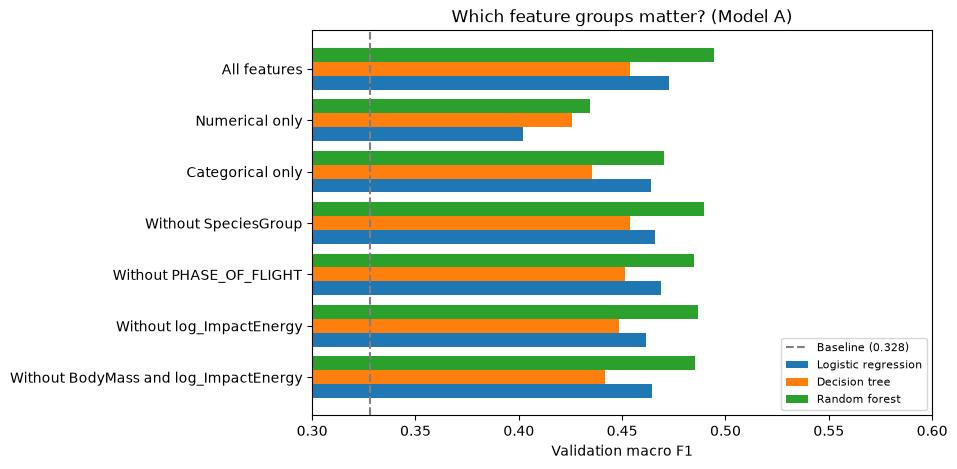

In [5]:
import matplotlib.pyplot as plt

table = feature_results.pivot(index="features", columns="model", values="val_f1_macro").loc[list(FEATURE_SETS)[::-1]]
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(table))
for k, model in enumerate(["Logistic regression", "Decision tree", "Random forest"]):
    ax.barh(y + (k - 1) * 0.27, table[model], height=0.27, label=model)
ax.set_yticks(y, table.index)
ax.set_xlim(0.3, max(0.6, table.values.max() + 0.02))
ax.axvline(0.328, color="grey", linestyle="--", label="Baseline (0.328)")
ax.set_xlabel("Validation macro F1")
ax.set_title("Which feature groups matter? (Model A)")
ax.legend(fontsize=8, loc="lower right")
fig.savefig("../plots/feature_groups.png", dpi=200, bbox_inches="tight")